# Week 3, Thursday: RandomizedSearchCV + Understanding the Tuning Results
dataset (**Breast Cancer**, built into scikit-learn). Today:
1. **RandomizedSearchCV** and how it compares with GridSearchCV.
2. **Plots** of the tuning results.
3. A **comparison table** across several classifiers.
4. How to **read** tuning results honestly (and a demo of how search results can fool you).

## 0. Setup (same split as Wednesday)

In [1]:
import numpy as np, pandas as pd, time
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import randint, loguniform
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
sns.set_theme(style='whitegrid')
np.random.seed(42)

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def pipe(model): return Pipeline([('scale', StandardScaler()), ('model', model)])
defaults = {'kNN': pipe(KNeighborsClassifier()), 'Decision Tree': pipe(DecisionTreeClassifier(random_state=42)),
            'SVM': pipe(SVC(random_state=42)), 'Random Forest': pipe(RandomForestClassifier(random_state=42))}
base = {}
for n, p in defaults.items():
    base[n] = dict(cv=cross_val_score(p, X_train, y_train, cv=cv).mean(), test=p.fit(X_train, y_train).score(X_test, y_test))
base = pd.DataFrame(base).T.round(3); base

,cv,test
kNN,0.967,0.979
Decision Tree,0.925,0.923
SVM,0.967,0.979
Random Forest,0.962,0.958


## 1. Grid vs Random: the idea
**GridSearchCV** tries every combination on a fixed grid. With many hyperparameters the number of combinations (and fits) **multiplies**. **RandomizedSearchCV** instead draws `n_iter` random combinations from **ranges or distributions**, so you control the budget directly.

A neat fact: usually only a **few** hyperparameters really matter. A 3x3 grid tests only **3 distinct values** of each hyperparameter, but 9 random points test **9 distinct values** of each.

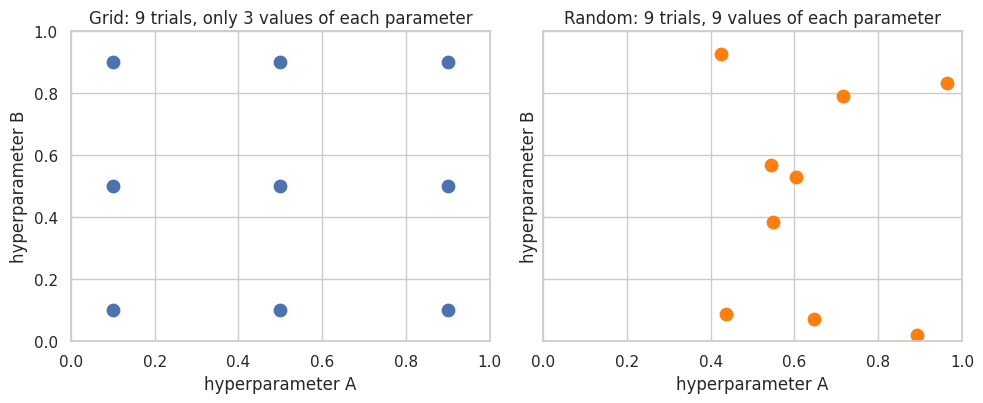

In [2]:
rng = np.random.RandomState(0)
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True, sharey=True)
gx, gy = np.meshgrid([0.1, 0.5, 0.9], [0.1, 0.5, 0.9])
ax[0].scatter(gx.ravel(), gy.ravel(), s=80); ax[0].set_title('Grid: 9 trials, only 3 values of each parameter')
rx, ry = rng.rand(9), rng.rand(9)
ax[1].scatter(rx, ry, s=80, color='tab:orange'); ax[1].set_title('Random: 9 trials, 9 values of each parameter')
for a in ax: a.set(xlabel='hyperparameter A', ylabel='hyperparameter B', xlim=(0, 1), ylim=(0, 1))
plt.tight_layout(); plt.show()

## 2. Same classifier, two search strategies: the SVM
Search space: `C` (strictness) and `gamma` (reach of each point's influence). Both matter on a **log scale**, so we sample them from a **log-uniform distribution** between `1e-2` and `1e3` (for C) and `1e-4` and `1` (for gamma).

In [3]:
svm_grid = {'model__C': [0.01, 0.1, 1, 10, 100, 1000], 'model__gamma': [1e-4, 1e-3, 1e-2, 1e-1, 1]}   # 6 x 5 = 30 combinations
t0 = time.time()
gs = GridSearchCV(pipe(SVC(kernel='rbf')), svm_grid, cv=cv, n_jobs=-1).fit(X_train, y_train); t_gs = time.time() - t0

svm_dist = {'model__C': loguniform(1e-2, 1e3), 'model__gamma': loguniform(1e-4, 1)}
t0 = time.time()
rs = RandomizedSearchCV(pipe(SVC(kernel='rbf')), svm_dist, n_iter=10, cv=cv, n_jobs=-1, random_state=0).fit(X_train, y_train); t_rs = time.time() - t0

cmp = pd.DataFrame({'trials': [30, 10], 'model fits': [150, 50], 'time (s)': [round(t_gs, 2), round(t_rs, 2)],
                    'best CV score': [round(gs.best_score_, 4), round(rs.best_score_, 4)],
                    'test accuracy': [round(gs.score(X_test, y_test), 4), round(rs.score(X_test, y_test), 4)]},
                   index=['GridSearchCV (30 combos)', 'RandomizedSearchCV (10 trials)'])
display(cmp)
print('Grid best  :', gs.best_params_)
print('Random best:', {k: round(float(v), 5) for k, v in rs.best_params_.items()})

,trials,model fits,time (s),best CV score,test accuracy
GridSearchCV (30 combos),30,150,3.06,0.9742,0.979
RandomizedSearchCV (10 trials),10,50,0.46,0.9719,0.979


Grid best  : {'model__C': 10, 'model__gamma': 0.001}
Random best: {'model__C': 10.32326, 'model__gamma': 0.01512}


In [4]:
scores, tests = [], []
for seed in range(8):
    r = RandomizedSearchCV(pipe(SVC(kernel='rbf')), svm_dist, n_iter=10, cv=cv, n_jobs=-1, random_state=seed).fit(X_train, y_train)
    scores.append(r.best_score_); tests.append(r.score(X_test, y_test))
print('Random search, 8 different seeds, 10 trials each')
print('best CV score :', np.round(scores, 4), ' -> grid (30 trials) got', round(gs.best_score_, 4))
print('test accuracy :', np.round(tests, 3))
print(f'CV score range across seeds: {min(scores):.4f} to {max(scores):.4f}')

Random search, 8 different seeds, 10 trials each
best CV score : [0.9719 0.9695 0.9742 0.9718 0.9719 0.9766 0.9766 0.9719]  -> grid (30 trials) got 0.9742
test accuracy : [0.979 0.986 0.979 0.986 0.986 0.979 0.986 0.986]
CV score range across seeds: 0.9695 to 0.9766


## 3. Random search where it really helps: a Random Forest
A Random Forest has several hyperparameters, so a full grid is huge. Here is a space with **5 x 6 x 4 x 4 x 3 = 1,440 combinations**, which would be **7,200 fits** with 5-fold CV. Random search tries only 40.

In [5]:
rf_dist = {'model__n_estimators': randint(50, 301), 'model__max_depth': [None, 3, 5, 8, 12, 20],
           'model__min_samples_split': randint(2, 21), 'model__min_samples_leaf': randint(1, 11),
           'model__max_features': ['sqrt', 'log2', 0.5]}
t0 = time.time()
rs_rf = RandomizedSearchCV(pipe(RandomForestClassifier(random_state=42)), rf_dist, n_iter=40, cv=cv, n_jobs=-1, random_state=0).fit(X_train, y_train)
t_rf = time.time() - t0
print(f'40 trials x 5 folds = 200 fits, {t_rf:.1f} s')
print('Best params:', {k.replace('model__', ''): v for k, v in rs_rf.best_params_.items()})
print('best CV score:', round(rs_rf.best_score_, 4), '| test accuracy:', round(rs_rf.score(X_test, y_test), 4),
      '| default forest: CV', base.loc['Random Forest', 'cv'], 'test', base.loc['Random Forest', 'test'])

40 trials x 5 folds = 200 fits, 45.9 s
Best params: {'max_depth': 12, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 245}
best CV score: 0.9578 | test accuracy: 0.958 | default forest: CV 0.962 test 0.958


## 4. Visualise the tuning
**(a) Heatmap** of the SVM grid: CV accuracy for each C and gamma.

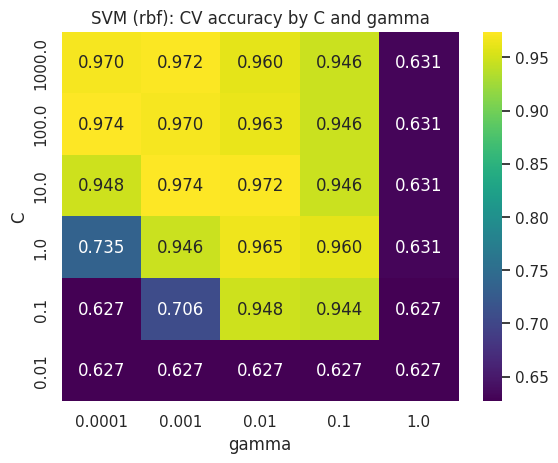

In [6]:
r = pd.DataFrame(gs.cv_results_)
heat = r.pivot(index='param_model__C', columns='param_model__gamma', values='mean_test_score').astype(float)
sns.heatmap(heat, annot=True, fmt='.3f', cmap='viridis'); plt.title('SVM (rbf): CV accuracy by C and gamma'); plt.ylabel('C'); plt.xlabel('gamma')
plt.gca().invert_yaxis(); plt.show()

**(b) Where did random search look?** Each dot is one random trial, coloured by its CV score.

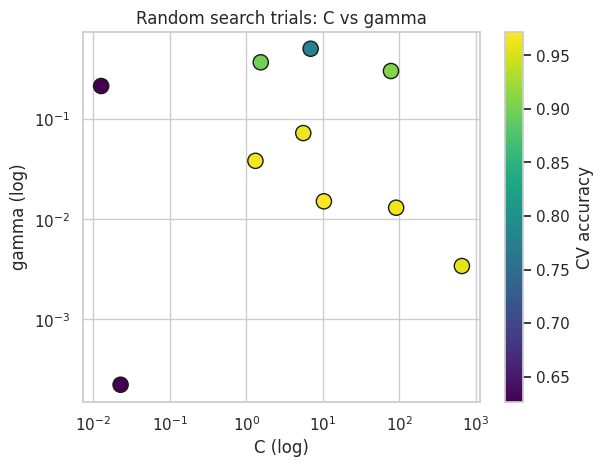

In [7]:
rr = pd.DataFrame(rs.cv_results_)
sc = plt.scatter(rr['param_model__C'].astype(float), rr['param_model__gamma'].astype(float), c=rr['mean_test_score'], cmap='viridis', s=120, edgecolor='k')
plt.xscale('log'); plt.yscale('log'); plt.colorbar(sc, label='CV accuracy'); plt.xlabel('C (log)'); plt.ylabel('gamma (log)')
plt.title('Random search trials: C vs gamma'); plt.show()

**(c) kNN: score versus k, with the fold-to-fold spread shaded.** (We re-run the grid from Wednesday.)

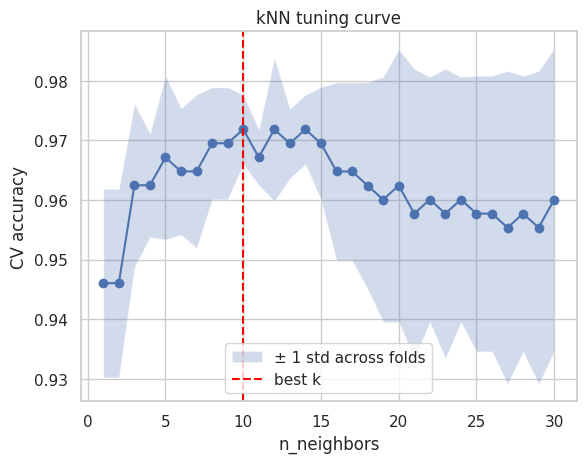

In [8]:
knn_grid = {'model__n_neighbors': list(range(1, 31)), 'model__weights': ['uniform', 'distance'], 'model__metric': ['euclidean', 'manhattan']}
gs_knn = GridSearchCV(defaults['kNN'], knn_grid, cv=cv, n_jobs=-1).fit(X_train, y_train)
rk = pd.DataFrame(gs_knn.cv_results_)
best_rows = rk.loc[rk.groupby('param_model__n_neighbors')['mean_test_score'].idxmax()]
ks = best_rows['param_model__n_neighbors'].astype(int).values; m = best_rows['mean_test_score'].values; s = best_rows['std_test_score'].values
plt.plot(ks, m, 'o-'); plt.fill_between(ks, m - s, m + s, alpha=0.25, label='± 1 std across folds')
plt.axvline(gs_knn.best_params_['model__n_neighbors'], color='red', ls='--', label='best k')
plt.xlabel('n_neighbors'); plt.ylabel('CV accuracy'); plt.title('kNN tuning curve'); plt.legend(); plt.show()

## 5. The comparison table (several classifiers, one place)
Tune the Decision Tree and kNN with grids, and put everything together: default score, tuned score, best parameters, search time.

In [9]:
tree_grid = {'model__max_depth': [1, 2, 3, 4, 5, 6, 8, 10, None], 'model__min_samples_leaf': [1, 2, 5, 10, 20], 'model__criterion': ['gini', 'entropy']}
t0 = time.time(); gs_tree = GridSearchCV(defaults['Decision Tree'], tree_grid, cv=cv, n_jobs=-1).fit(X_train, y_train); t_tree = time.time() - t0
t0 = time.time(); gs_knn2 = GridSearchCV(defaults['kNN'], knn_grid, cv=cv, n_jobs=-1).fit(X_train, y_train); t_knn = time.time() - t0

rows = [('kNN', 'Grid', gs_knn2, t_knn), ('Decision Tree', 'Grid', gs_tree, t_tree), ('SVM', 'Grid', gs, t_gs),
        ('SVM', 'Random', rs, t_rs), ('Random Forest', 'Random', rs_rf, t_rf)]
table = pd.DataFrame([{'model': n, 'search': how, 'default CV': base.loc[n, 'cv'], 'tuned CV': round(s.best_score_, 3),
                       'default test': base.loc[n, 'test'], 'tuned test': round(s.score(X_test, y_test), 3),
                       'time (s)': round(t, 1)} for n, how, s, t in rows])
table['test change'] = (table['tuned test'] - table['default test']).round(3)
display(table)
for n, how, s, t in rows: print(f'{n:14s} ({how:6s}):', {k.replace('model__', ''): (round(float(v), 4) if isinstance(v, float) else v) for k, v in s.best_params_.items()})

,model,search,default CV,tuned CV,default test,tuned test,time (s),test change
0,kNN,Grid,0.967,0.972,0.979,0.965,3.2,-0.014
1,Decision Tree,Grid,0.925,0.941,0.923,0.895,5.5,-0.028
2,SVM,Grid,0.967,0.974,0.979,0.979,3.1,0.000
3,SVM,Random,0.967,0.972,0.979,0.979,0.5,0.000
4,Random Forest,Random,0.962,0.958,0.958,0.958,45.9,0.000


kNN            (Grid  ): {'metric': 'euclidean', 'n_neighbors': 10, 'weights': 'uniform'}
Decision Tree  (Grid  ): {'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 2}
SVM            (Grid  ): {'C': 10, 'gamma': 0.001}
SVM            (Random): {'C': 10.3233, 'gamma': 0.0151}
Random Forest  (Random): {'max_depth': 12, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 245}


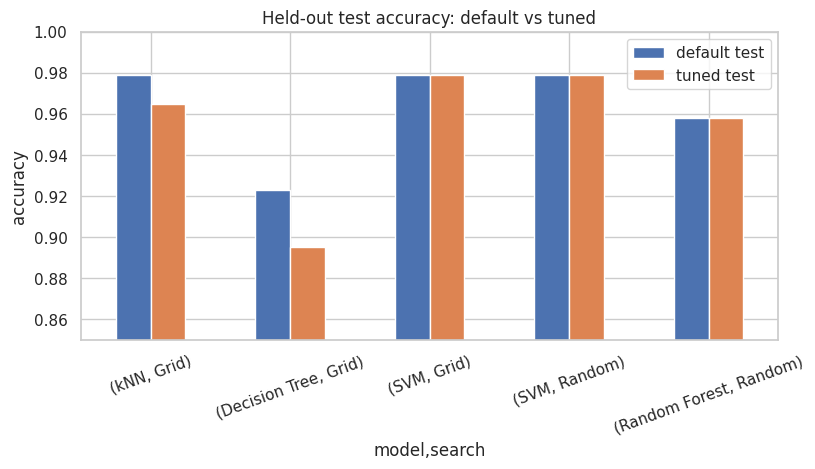

In [10]:
table.set_index(['model', 'search'])[['default test', 'tuned test']].plot.bar(figsize=(9, 4), ylim=(0.85, 1.0), title='Held-out test accuracy: default vs tuned')
plt.ylabel('accuracy'); plt.xticks(rotation=20); plt.show()

## 6. Reading the results honestly
**Check 1: is the gain bigger than the noise?** The test set has **143** rows, so one row is about **0.007**. Compare each `test change` with that, and with the CV standard deviation (about 0.005-0.02).

**Check 2: is the best value on the edge of the grid?** If the best value is the smallest or largest you tried, the true best may lie outside, so widen the grid (unless the value is already the smallest or largest *allowed*, such as `min_samples_leaf = 1`). This helper checks it for you:

In [11]:
def edge_check(search, name):
    res = pd.DataFrame(search.cv_results_); out = []
    for p, v in search.best_params_.items():
        col = res['param_' + p]
        try:
            vals = col.astype(float)
            if v == vals.min() or v == vals.max(): out.append(f'{p.replace("model__","")}={v:g} is at the EDGE of what was tried')
        except (ValueError, TypeError): pass
    print(f'{name:22s}', '; '.join(out) if out else 'best values are inside the tried range')
for n, how, s, t in rows: edge_check(s, f'{n} ({how})')

kNN (Grid)             best values are inside the tried range
Decision Tree (Grid)   best values are inside the tried range
SVM (Grid)             best values are inside the tried range
SVM (Random)           best values are inside the tried range
Random Forest (Random) min_samples_leaf=1 is at the EDGE of what was tried


In [12]:
y_shuffled = pd.Series(np.random.RandomState(0).permutation(y_train.values), index=y_train.index)
gs_noise = GridSearchCV(defaults['kNN'], knn_grid, cv=cv, n_jobs=-1).fit(X_train, y_shuffled)
print('Labels are RANDOM, so no model can beat guessing the majority class (rate =', round(y_shuffled.value_counts(normalize=True).max(), 3), ')')
print('Best CV score found by searching 120 settings:', round(gs_noise.best_score_, 3))
print('Mean CV score over all 120 settings           :', round(pd.DataFrame(gs_noise.cv_results_)['mean_test_score'].mean(), 3))

Labels are RANDOM, so no model can beat guessing the majority class (rate = 0.627 )
Best CV score found by searching 120 settings: 0.629
Mean CV score over all 120 settings           : 0.579
